# Phase 17 — Explain population differences and audit prediction reliability
Owner: Shafin. CPU analysis of Phase 16 saved predictions; no training, inference or tuning. Inputs and outputs stay in this contribution folder.

**Decision after Phase 16:** CNN errors on removed candidates were modestly higher, while K562 correlations were higher too. Higher target variability can coexist with higher correlation and higher absolute error. Examine composition and reliability rather than assuming a major failure on removed DNA.

This phase has three exploratory tasks: (1) standardize retained/removed absolute errors to a shared activity/GC/repetitiveness composition; (2) test whether three-seed disagreement identifies larger errors; (3) empirically audit simple nominal 90% prediction intervals. DNABERT-2 remains pending original fine-tuned weights.

**Important:** the calibration/audit group assignment was frozen in Phase 16 before new inference. Calibration records were not used to fit the checkpoints or select their epochs. However, retained benchmark results and all-population Phase 16 summaries have already been examined. These are retrospective reliability diagnostics, not a prospective confirmation. Genomic dependence and population shift prevent an unconditional conformal coverage guarantee. Seed spread is not total biological or assay uncertainty.

In [1]:
from pathlib import Path
import os,sys,json,hashlib,math,gzip
import numpy as np,pandas as pd
from scipy.stats import spearmanr
ROOT=Path(r"D:\Aditta Thesis\For Shafin\Shafin's Contribution").resolve()
assert Path(sys.executable).resolve()==Path(r'C:\Users\User\.conda\envs\enhancer\python.exe').resolve()
OUT=ROOT/'phase17_outputs';OUT.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR']=str(OUT/'matplotlib_cache')
P16=ROOT/'phase16_outputs'
def fsha(p):
 with Path(p).open('rb') as f:return hashlib.file_digest(f,'sha256').hexdigest()
def dump(name,obj):
 raw=json.dumps(obj,indent=2,sort_keys=True,allow_nan=False)+'\n';p=OUT/name
 if name.startswith('frozen_protocol') and p.exists():assert p.read_text(encoding='utf8')==raw
 else:p.write_text(raw,encoding='utf8')
def table(name,d):d.to_csv(OUT/name,index=False,float_format='%.12g')
parent=json.loads((P16/'phase16_summary.json').read_text())
for name,h in parent['outputs'].items():
 if name!='execution_log.txt':assert fsha(P16/name)==h,name
S=pd.read_csv(P16/'ensemble_predictions_and_metadata.csv.gz')
assert S.seeds.eq(3).all() and S.groupby(['cell_line','record_id']).model.nunique().eq(2).all()
S=S[S.eligible_primary].copy()
T=pd.read_csv(ROOT/'phase14_outputs/training_only_subgroup_thresholds.csv')
CK=pd.read_csv(P16/'loaded_checkpoint_metadata.csv')
SPEC={'name':'phase17_composition_seed_reliability_v1','parent':parent['protocol_sha256'],
 'prediction_semantic_sha256':hashlib.sha256(gzip.decompress((P16/'ensemble_predictions_and_metadata.csv.gz').read_bytes())).hexdigest(),
 'standardization':'Phase14 activity 20/80 bins x fixed GC bins x homopolymer >=6; both populations n>=50 in each stratum; pooled common-support weights',
 'disagreement':'sample SD of three frozen seed predictions; descriptive Spearman with absolute error',
 'retention_cutoffs':'25/50/75th percentiles of seed spread in retained calibration groups; no outcome-based selection',
 'prediction_intervals':'nominal 90%; finite-sample corrected quantile; constant-width and normalized by max(seed_sd,0.05*training_target_SD)',
 'calibration_sources':['retained','removed'],'partition':'Phase16 frozen genomic/identity-group hash 30% calibration; 70% audit',
 'inferential_scope':'retrospective diagnostics; no formal exchangeability, future coverage or individual-sequence confidence guarantee',
 'bootstrap_repeats':1000,'bootstrap_seed':2026101717,'dnabert2':'pending original fine-tuned weights'}
# Retain the initial compressed-container lock. Gzip timestamps can change on
# identical-data reruns; lock the uncompressed CSV instead without changing decisions.
initial=json.loads((OUT/'frozen_protocol.json').read_text()) if (OUT/'frozen_protocol.json').exists() else None
if initial:
 old_decisions={k:v for k,v in initial.items() if k!='prediction_sha256'}
 new_decisions={k:v for k,v in SPEC.items() if k!='prediction_semantic_sha256'}
 assert old_decisions==new_decisions,'Scientific decisions changed.'
dump('frozen_protocol_semantic_hash.json',SPEC)
LOCK=hashlib.sha256(json.dumps(SPEC,sort_keys=True,separators=(',',':')).encode()).hexdigest()
for cell,g in S.groupby('cell_line'):
 t=T[T.protocol.eq('9b')&T.cell_line.eq(cell)].iloc[0]
 S.loc[g.index,'activity_band']=np.where(g.mean_log2_activity<t.training_activity_q20,'low',np.where(g.mean_log2_activity>t.training_activity_q80,'high','middle'))
 S.loc[g.index,'gc_band']=pd.cut(g.gc_fraction,[0,.35,.45,.55,.65,1],include_lowest=True).astype(str)
 S.loc[g.index,'homopolymer_band']=np.where(g.max_homopolymer>=6,'at_least_6','below_6')
S['stratum']=S.activity_band+'|'+S.gc_band+'|'+S.homopolymer_band
S['absolute_error']=abs(S.prediction-S.mean_log2_activity)
S['squared_error']=(S.prediction-S.mean_log2_activity)**2
assert S.groupby(['cell_line','resampling_group']).followup_partition.nunique().max()==1
print('Fixed Phase17 protocol',LOCK)
print(S.drop_duplicates(['cell_line','record_id']).groupby(['cell_line','population','followup_partition']).size())

Fixed Phase17 protocol 8ccc02920a8bf5eb5e3fcd1c55084cede3c786c69562222501ca8b171dda144d
cell_line  population  followup_partition
HepG2      removed     audit                 5932
                       calibration           2504
           retained    audit                 6353
                       calibration           2695
K562       removed     audit                 8930
                       calibration           3772
           retained    audit                 9190
                       calibration           3955
dtype: int64


## 1. Standardize the comparison to a common observed composition
Compare MAE and RMSE after giving both populations the same stratum weights. Activity/GC cutoffs come from Phase 14, not optimization of Phase 16 performance. A stratum must contain at least 50 retained and 50 removed records. The reference mixture is the pooled population within common support. Report excluded support explicitly.

This is descriptive standardization, not a causal adjustment or evidence that composition explains all differences. Activity is an observed outcome; these weights cannot be used as a deployment-time rule. Bootstrap whole genomic/identity groups and hold the observed support and reference mixture fixed.

In [2]:
standard_rows=[];support_rows=[];ci_rows=[]
for (cell,model),g in S.groupby(['cell_line','model']):
 counts=g.groupby(['stratum','population']).size().unstack(fill_value=0)
 keep=counts.index[(counts.retained>=50)&(counts.removed>=50)].tolist()
 assert keep
 weights=counts.loc[keep].sum(axis=1);weights=weights/weights.sum()
 means=g.groupby(['stratum','population'])[['absolute_error','squared_error']].mean()
 point={}
 for pop in ['retained','removed']:
  p=means.xs(pop,level='population').loc[keep]
  point[pop]=np.array([np.sum(weights*p.absolute_error),np.sqrt(np.sum(weights*p.squared_error))])
  h=g[g.population.eq(pop)]
  support_rows.append(dict(cell_line=cell,model=model,population=pop,total_n=len(h),common_support_n=int(h.stratum.isin(keep).sum()),
    supported_fraction=float(h.stratum.isin(keep).mean()),common_strata=len(keep),total_strata=len(counts)))
  standard_rows.append(dict(cell_line=cell,model=model,population=pop,raw_mae=float(h.absolute_error.mean()),
   raw_rmse=float(np.sqrt(h.squared_error.mean())),standardized_mae=point[pop][0],standardized_rmse=point[pop][1]))
 keys=sorted(g.resampling_group.unique());columns=pd.MultiIndex.from_product([['retained','removed'],keep,['n','ae','se']])
 tmp=g[g.stratum.isin(keep)].assign(n=1.,ae=lambda d:d.absolute_error,se=lambda d:d.squared_error)
 moments=tmp.groupby(['resampling_group','population','stratum'])[['n','ae','se']].sum().unstack(['population','stratum'])
 moments=moments.reorder_levels([1,2,0],axis=1).reindex(index=keys,columns=columns,fill_value=0).fillna(0).to_numpy()
 rng=np.random.default_rng(SPEC['bootstrap_seed']);draws=[]
 for start in range(0,1000,50):
  b=np.stack([np.bincount(rng.integers(0,len(keys),len(keys)),minlength=len(keys)) for _ in range(50)])
  m=(b@moments).reshape(50,2,len(keep),3);n=m[:,:,:,0]
  assert (n>0).all()
  mae=(m[:,:,:,1]/n*weights.to_numpy()).sum(axis=2)
  rmse=np.sqrt((m[:,:,:,2]/n*weights.to_numpy()).sum(axis=2))
  draws.append(np.column_stack([mae[:,1]-mae[:,0],rmse[:,1]-rmse[:,0]]))
 draws=np.concatenate(draws)
 for j,metric in enumerate(['mae','rmse']):
  lo,hi=np.quantile(draws[:,j],[.025,.975]);ci_rows.append(dict(cell_line=cell,model=model,metric=metric,
    removed_minus_retained=point['removed'][j]-point['retained'][j],lo=lo,hi=hi))
STD=pd.DataFrame(standard_rows);SUPPORT=pd.DataFrame(support_rows);STDCI=pd.DataFrame(ci_rows)
table('composition_standardized_errors.csv',STD);table('composition_common_support.csv',SUPPORT);table('composition_conditional_contrasts.csv',STDCI)
print(STD.round(5).to_string(index=False));print(STDCI.round(5).to_string(index=False));print(SUPPORT.round(4).to_string(index=False))

cell_line  model population  raw_mae  raw_rmse  standardized_mae  standardized_rmse
    HepG2 legnet   retained  0.39294   0.53796           0.38974            0.53324
    HepG2 legnet    removed  0.40008   0.54874           0.39664            0.54346
    HepG2 mprann   retained  0.39591   0.54139           0.39241            0.53633
    HepG2 mprann    removed  0.39931   0.54578           0.39583            0.54088
     K562 legnet   retained  0.23201   0.30543           0.23278            0.30694
     K562 legnet    removed  0.23876   0.31374           0.23656            0.31065
     K562 mprann   retained  0.23937   0.31512           0.23924            0.31540
     K562 mprann    removed  0.24439   0.32177           0.24225            0.31857
cell_line  model metric  removed_minus_retained       lo      hi
    HepG2 legnet    mae                 0.00690 -0.00284 0.01649
    HepG2 legnet   rmse                 0.01021 -0.00594 0.02754
    HepG2 mprann    mae                 0.00342 -

## 2. Does seed disagreement flag unreliable predictions?
Measure the association between seed SD and absolute error on the audit portion. Define low-disagreement cutoffs from retained calibration predictions alone, without their labels. Apply those same cutoffs to retained and removed audit candidates. Report both the fraction accepted and its error; choosing the best cutoff after seeing these results would need a new evaluation.

Low disagreement does not prove correctness: all three seeds can make the same mistake. Here we audit that limitation rather than claiming a calibrated uncertainty model.

In [3]:
assoc=[];select=[];cutrows=[]
for (cell,model),allg in S.groupby(['cell_line','model']):
 cal=allg[allg.population.eq('retained')&allg.followup_partition.eq('calibration')]
 cutoffs={q:float(cal.seed_sd.quantile(q)) for q in [.25,.5,.75]}
 for q,c in cutoffs.items():cutrows.append(dict(cell_line=cell,model=model,calibration_quantile=q,seed_sd_cutoff=c,calibration_n=len(cal)))
 for pop,g in allg[allg.followup_partition.eq('audit')].groupby('population'):
  assoc.append(dict(cell_line=cell,model=model,population=pop,n=len(g),
    spearman_seed_sd_absolute_error=float(spearmanr(g.seed_sd,g.absolute_error).statistic),
    mean_seed_sd=float(g.seed_sd.mean()),mean_absolute_error=float(g.absolute_error.mean())))
  for q,cutoff in [(q,c) for q,c in cutoffs.items()]+[(1.,float('inf'))]:
   h=g[g.seed_sd<=cutoff]
   select.append(dict(cell_line=cell,model=model,population=pop,calibration_quantile=q,accepted_n=len(h),audit_n=len(g),
    accepted_fraction=len(h)/len(g),mae=float(h.absolute_error.mean()),rmse=float(np.sqrt(h.squared_error.mean())),
    target_sd=float(h.mean_log2_activity.std(ddof=0))))
ASSOC=pd.DataFrame(assoc);SELECT=pd.DataFrame(select)
table('seed_disagreement_error_association.csv',ASSOC);table('fixed_cutoff_selective_errors.csv',SELECT);table('retained_calibration_spread_cutoffs.csv',pd.DataFrame(cutrows))
print(ASSOC.round(5).to_string(index=False));print(SELECT.round(5).to_string(index=False))

cell_line  model population    n  spearman_seed_sd_absolute_error  mean_seed_sd  mean_absolute_error
    HepG2 legnet    removed 5932                          0.12398       0.16703              0.39770
    HepG2 legnet   retained 6353                          0.12475       0.16781              0.39923
    HepG2 mprann    removed 5932                          0.10394       0.15357              0.39781
    HepG2 mprann   retained 6353                          0.13288       0.15558              0.39912
     K562 legnet    removed 8930                          0.08773       0.09481              0.23830
     K562 legnet   retained 9190                          0.08175       0.09321              0.23116
     K562 mprann    removed 8930                          0.13496       0.09639              0.24331
     K562 mprann   retained 9190                          0.15511       0.09702              0.23809
cell_line  model population  calibration_quantile  accepted_n  audit_n  accepted_fraction  

## 3. Empirical nominal 90% interval audit
For each fixed model, estimate a residual quantile using only the calibration groups, and evaluate coverage and width on the disjoint audit groups. Compare an equal-width interval with an interval scaled by three-seed disagreement. The scale floor is fixed at 5% of the original training-target SD, not tuned on test errors. Quantiles use the standard finite-sample order-statistic correction.

Primary calibration source is retained candidates: does calibration transfer to removed candidates? Removed-candidate calibration is a labelled secondary sensitivity. No audit labels enter interval fitting. Group separation avoids sharing nearby/identical sequences between calibration and audit within a cell, but does not establish exchangeability. We report measured coverage, not a guaranteed 90% success rate. Coverage is marginal over a population; even ideal marginal coverage would not certify each sequence.

Methodological reference: Barber, Candès, Ramdas and Tibshirani (2023), *Conformal prediction beyond exchangeability*, Annals of Statistics 51:816–845, https://doi.org/10.1214/23-AOS2276 . This notebook does not implement their weighted method or assert its guarantees.

In [4]:
def corrected_quantile(values,alpha=.1):
 v=np.sort(np.asarray(values,float));k=min(len(v),math.ceil((len(v)+1)*(1-alpha)))
 return float(v[k-1])
interval_rows=[];subcoverage=[];parameter_rows=[];interval_predictions=[]
for (cell,model),allg in S.groupby(['cell_line','model']):
 scale=float(CK[CK.job.str.contains(f'9b_{cell}_{model}_')].target_scale.iloc[0]);floor=.05*scale
 for source in ['retained','removed']:
  cal=allg[allg.population.eq(source)&allg.followup_partition.eq('calibration')]
  assert len(cal)>100
  for method in ['constant_width','seed_scaled']:
   denom=np.ones(len(cal)) if method=='constant_width' else np.maximum(cal.seed_sd.to_numpy(),floor)
   q=corrected_quantile(cal.absolute_error.to_numpy()/denom)
   parameter_rows.append(dict(cell_line=cell,model=model,calibration_source=source,method=method,n_calibration=len(cal),
     quantile=q,seed_sd_floor=floor,nominal_coverage=.9))
   for pop,g in allg[allg.followup_partition.eq('audit')].groupby('population'):
    assert set(cal.resampling_group).isdisjoint(g.resampling_group)
    d=np.ones(len(g)) if method=='constant_width' else np.maximum(g.seed_sd.to_numpy(),floor)
    half=q*d;covered=g.absolute_error.to_numpy()<=half
    h=g.assign(covered=covered,interval_width=2*half)
    interval_rows.append(dict(cell_line=cell,model=model,calibration_source=source,audit_population=pop,method=method,
      n=len(g),nominal_coverage=.9,empirical_coverage=float(np.mean(covered)),mean_width=float(np.mean(2*half)),
      median_width=float(np.median(2*half))))
    interval_predictions.append(pd.DataFrame({'record_id':g.record_id,'cell_line':cell,'model':model,'calibration_source':source,'method':method,
      'audit_population':pop,'target':g.mean_log2_activity,'prediction':g.prediction,'lower':g.prediction-half,'upper':g.prediction+half,'covered':covered}))
    for family in ['activity_band','gc_band','homopolymer_band']:
     for subgroup,s in h.groupby(family):
      row=dict(cell_line=cell,model=model,calibration_source=source,audit_population=pop,method=method,family=family,subgroup=subgroup,n=len(s),suppressed=len(s)<100)
      if len(s)>=100:row.update(empirical_coverage=float(s.covered.mean()),mean_width=float(s.interval_width.mean()))
      subcoverage.append(row)
INT=pd.DataFrame(interval_rows)
table('interval_calibration_parameters.csv',pd.DataFrame(parameter_rows));table('interval_audit_coverage.csv',INT)
table('interval_subgroup_coverage.csv',pd.DataFrame(subcoverage));table('audit_prediction_intervals.csv.gz',pd.concat(interval_predictions,ignore_index=True))
print(INT[INT.calibration_source.eq('retained')].round(5).to_string(index=False))

cell_line  model calibration_source audit_population         method    n  nominal_coverage  empirical_coverage  mean_width  median_width
    HepG2 legnet           retained          removed constant_width 5932               0.9             0.88520     1.60992       1.60992
    HepG2 legnet           retained         retained constant_width 6353               0.9             0.88053     1.60992       1.60992
    HepG2 legnet           retained          removed    seed_scaled 5932               0.9             0.88739     2.31574       2.09666
    HepG2 legnet           retained         retained    seed_scaled 6353               0.9             0.88698     2.32556       2.09197
    HepG2 mprann           retained          removed constant_width 5932               0.9             0.88739     1.63765       1.63765
    HepG2 mprann           retained         retained constant_width 6353               0.9             0.89060     1.63765       1.63765
    HepG2 mprann           retained      

## 4. Save findings, limitations and reproducible figures
Neither a higher correlation nor low seed disagreement alone establishes more accurate activity values. Do not tune rejection cutoffs, choose an interval method or select a model from these audit outcomes and then reuse the same audit set as an untouched test. This phase supports a bounded reliability discussion; a prospective study would need a newly reserved evaluation population.

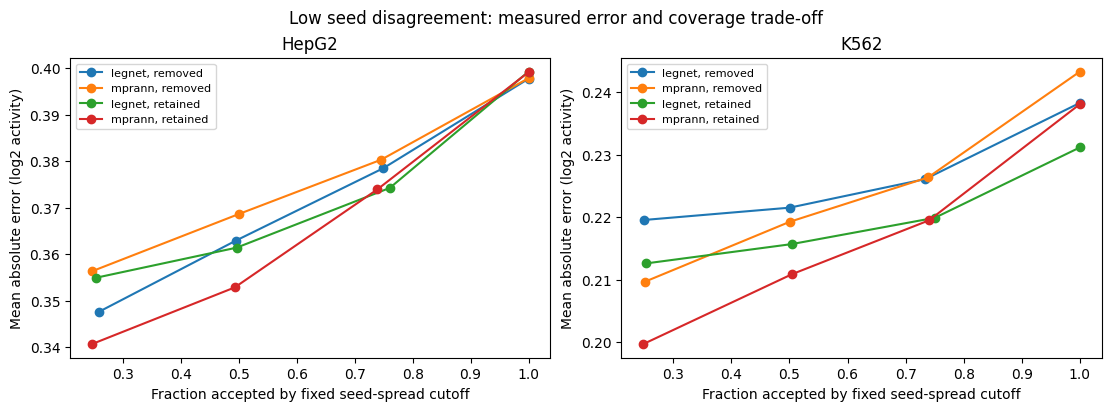

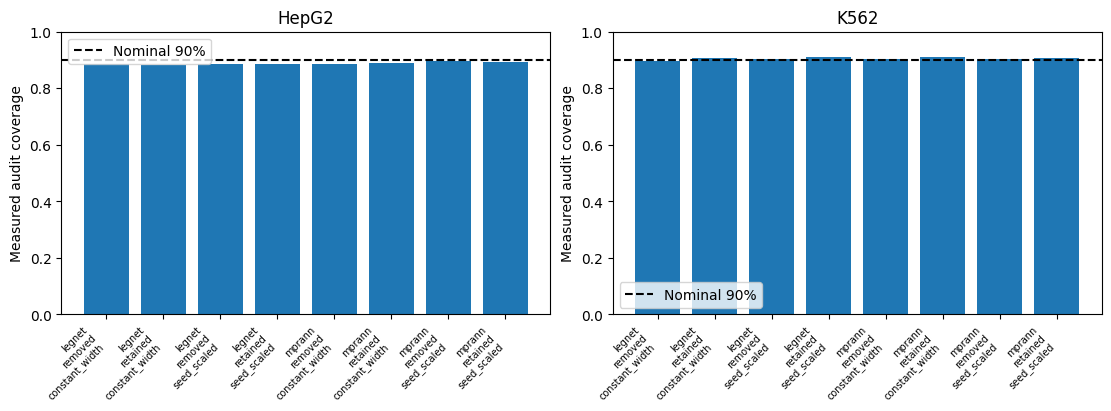

Phase 17 completed: composition, disagreement and empirical interval audits.


In [5]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,cell in zip(axes,['HepG2','K562']):
 for (pop,model),g in SELECT[SELECT.cell_line.eq(cell)].groupby(['population','model']):
  g=g.sort_values('accepted_fraction');ax.plot(g.accepted_fraction,g.mae,marker='o',label=f'{model}, {pop}')
 ax.set_title(cell);ax.set_xlabel('Fraction accepted by fixed seed-spread cutoff');ax.set_ylabel('Mean absolute error (log2 activity)');ax.legend(fontsize=8)
fig.suptitle('Low seed disagreement: measured error and coverage trade-off')
fig.savefig(OUT/'seed_disagreement_selective_errors.png',dpi=180);fig.savefig(OUT/'seed_disagreement_selective_errors.pdf');plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,cell in zip(axes,['HepG2','K562']):
 part=INT[INT.cell_line.eq(cell)&INT.calibration_source.eq('retained')]
 labels=[f'{r.model}\n{r.audit_population}\n{r.method}' for r in part.itertuples()]
 ax.bar(np.arange(len(part)),part.empirical_coverage);ax.axhline(.9,color='black',linestyle='--',label='Nominal 90%')
 ax.set_xticks(np.arange(len(part)),labels,rotation=45,ha='right',fontsize=7);ax.set_ylim(0,1);ax.set_ylabel('Measured audit coverage');ax.set_title(cell);ax.legend()
fig.savefig(OUT/'nominal90_empirical_coverage.png',dpi=180);fig.savefig(OUT/'nominal90_empirical_coverage.pdf');plt.show()
dump('phase17_summary.json',dict(status='completed_for_CNNs_DNABERT2_pending',protocol_sha256=LOCK,training_launched=False,
 composition_rows=len(STD),reliability_rows=len(ASSOC),interval_audit_rows=len(INT),
 retained_calibration_never_used_for_checkpoint_fitting=True,audit_used_for_interval_fitting=False,
 limitation='Retrospective results; population/region dependence; empirical marginal coverage, no universal or per-sequence guarantee',
 outputs={p.name:fsha(p) for p in OUT.iterdir() if p.is_file() and p.name!='phase17_summary.json'}))
print('Phase 17 completed: composition, disagreement and empirical interval audits.')